ACTIVITY 1

Accuracy : 0.9664
Precision: 0.9107
Recall   : 0.9273
F1-score : 0.9189
ROC-AUC  : 0.9924


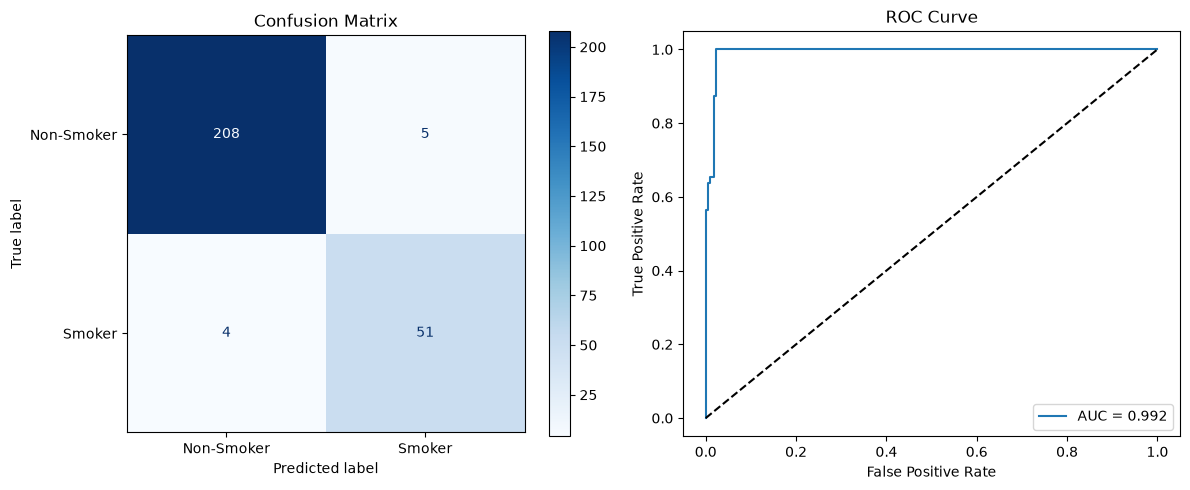

In [10]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

df = pd.read_csv("Medical Cost Personal Datasets.csv")
df["smoker"] = df["smoker"].map({"no": 0, "yes": 1})
df["sex"] = df["sex"].map({"female": 0, "male": 1})
df = pd.get_dummies(df, columns=["region"], drop_first=True)

X = df.drop(columns="smoker")
y = df["smoker"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num = ["age", "bmi", "children", "charges"]
sc = StandardScaler()
X_train[num] = sc.fit_transform(X_train[num])
X_test[num] = sc.transform(X_test[num])

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.close("all")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Smoker", "Smoker"]).plot(ax=ax[0], cmap="Blues")
ax[0].set_title("Confusion Matrix")

ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve")
ax[1].legend()

plt.tight_layout()
plt.show()

ACTIVITY 2


MODEL RESULTS
              Model  Train R2  Test R2  Test MAE  Test RMSE
  Linear Regression    0.7711   0.8060    0.0446     0.0630
Polynomial Degree 2    0.7715   0.8066    0.0448     0.0629
Polynomial Degree 3    0.7725   0.8051    0.0448     0.0631
Polynomial Degree 4    0.7726   0.8051    0.0448     0.0631


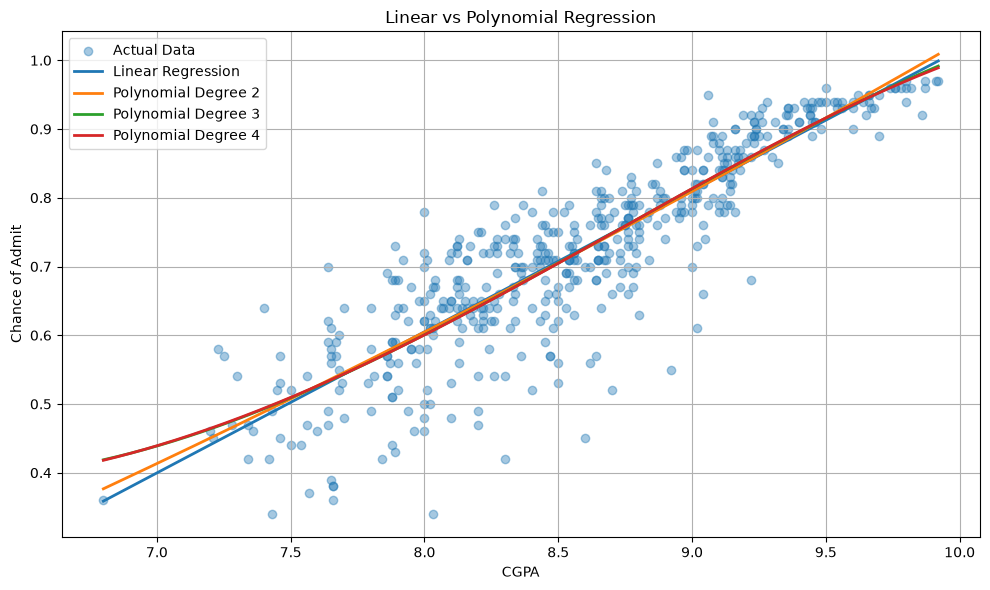

In [11]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("Admission_Predict.csv")
df.columns = df.columns.str.strip()

X = df[["CGPA"]]
y = df["Chance of Admit"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Degree 2": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Polynomial Degree 3": make_pipeline(PolynomialFeatures(3), LinearRegression()),
    "Polynomial Degree 4": make_pipeline(PolynomialFeatures(4), LinearRegression())
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    train_r2 = r2_score(y_train, train_prediction)
    test_r2 = r2_score(y_test, test_prediction)
    mae = mean_absolute_error(y_test, test_prediction)
    rmse = np.sqrt(mean_squared_error(y_test, test_prediction))

    results.append([name, train_r2, test_r2, mae, rmse])

results_df = pd.DataFrame(results, columns=["Model", "Train R2", "Test R2", "Test MAE", "Test RMSE"])

print("\nMODEL RESULTS")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

x_values = np.linspace(X["CGPA"].min(), X["CGPA"].max(), 300).reshape(-1, 1)
x_values_df = pd.DataFrame(x_values, columns=["CGPA"])

plt.close("all")
plt.figure(figsize=(10, 6))

plt.scatter(X["CGPA"], y, alpha=0.4, label="Actual Data")

for name, model in models.items():
    prediction = model.predict(x_values_df)
    plt.plot(x_values, prediction, linewidth=2, label=name)

plt.xlabel("CGPA")
plt.ylabel("Chance of Admit")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()